# Chuong 3. Mô hình hồi quy trong kỹ thuật công trình
Mã lệnh của các ví dụ trong giáo trình Khoa học dữ liệu công trình, chạy tuần tự từ trên xuống.

[Mở trên Google Colab](https://colab.research.google.com/github/ngochoautc/khoa-hoc-du-lieu-cong-trinh/blob/main/notebooks/Chuong3.ipynb)

## HỒI QUY TUYẾN TÍNH VÀ HỒI QUY BỘI

### Mô hình hồi quy tuyến tính đơn

### Phương pháp bình phương nhỏ nhất

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Vi du: ty le N/X va cuong do nen 28 ngay (MPa)
nx = np.array([0.40, 0.45, 0.50, 0.55, 0.60, 0.65])
fc = np.array([45.8, 41.2, 38.6, 34.5, 31.9, 27.4])
n = len(nx)
x_tb, y_tb = nx.mean(), fc.mean()
Sxx = np.sum((nx - x_tb) ** 2)
Sxy = np.sum((nx - x_tb) * (fc - y_tb))
b1 = Sxy / Sxx                 # he so goc (MPa)
b0 = y_tb - b1 * x_tb          # he so chan (MPa)
print(f"x_tb = {x_tb:.3f}, y_tb = {y_tb:.3f} MPa")
print(f"Sxx = {Sxx:.5f}, Sxy = {Sxy:.3f} MPa")
print(f"b1 = {b1:.2f} MPa, b0 = {b0:.2f} MPa")

x_tb = 0.525, y_tb = 36.567 MPa
Sxx = 0.04375, Sxy = -3.100 MPa
b1 = -70.86 MPa, b0 = 73.77 MPa


### Đánh giá chất lượng mô hình

In [2]:
fc_hat = b0 + b1 * nx         # gia tri du bao (MPa)
e = fc - fc_hat                # phan du (MPa)
SS_tong = np.sum((fc - y_tb) ** 2)
SS_du = np.sum(e ** 2)
SS_hq = SS_tong - SS_du
R2 = 1 - SS_du / SS_tong
s = np.sqrt(SS_du / (n - 2))   # sai so chuan cua hoi quy
e_rmse = np.sqrt(SS_du / n)    # RMSE (muc 5.1)
print(f"SS_tong = {SS_tong:.2f}, SS_hq = {SS_hq:.2f}, "
      f"SS_du = {SS_du:.3f} (MPa^2)")
print(f"R2 = {R2:.4f}, r = {np.corrcoef(nx, fc)[0, 1]:.3f}")
print(f"s = {s:.3f} MPa, RMSE = {e_rmse:.3f} MPa")

SS_tong = 220.93, SS_hq = 219.66, SS_du = 1.276 (MPa^2)
R2 = 0.9942, r = -0.997
s = 0.565 MPa, RMSE = 0.461 MPa


### Suy diễn thống kê về hệ số hồi quy

In [3]:
btd = n - 2                    # so bac tu do
t_q = stats.t.ppf(0.975, btd)  # phan vi 97.5 %
se_b1 = s / np.sqrt(Sxx)
t_b1 = b1 / se_b1
p_b1 = 2 * stats.t.sf(abs(t_b1), btd)
print(f"se(b1) = {se_b1:.2f} MPa, t = {t_b1:.2f}, "
      f"df = {btd}, p = {p_b1:.2e}")
print(f"t(0.975; {btd}) = {t_q:.3f}")
print(f"KTC 95% cua b1: [{b1 - t_q * se_b1:.2f}; "
      f"{b1 + t_q * se_b1:.2f}] MPa")
x0 = 0.52
y0 = b0 + b1 * x0
h2 = 1 / n + (x0 - x_tb) ** 2 / Sxx
k_tb = t_q * s * np.sqrt(h2)       # cho gia tri trung binh
k_db = t_q * s * np.sqrt(1 + h2)   # cho mot to mau moi
print(f"Du bao tai N/X = {x0}: {y0:.2f} MPa")
print(f"KTC 95% gia tri trung binh: [{y0 - k_tb:.2f}; "
      f"{y0 + k_tb:.2f}] MPa")
print(f"Khoang du bao 95% to mau moi: [{y0 - k_db:.2f}; "
      f"{y0 + k_db:.2f}] MPa")

se(b1) = 2.70 MPa, t = -26.24, df = 4, p = 1.25e-05
t(0.975; 4) = 2.776
KTC 95% cua b1: [-78.35; -63.36] MPa
Du bao tai N/X = 0.52: 36.92 MPa
KTC 95% gia tri trung binh: [36.28; 37.56] MPa
Khoang du bao 95% to mau moi: [35.23; 38.62] MPa


### Hồi quy tuyến tính bội và kiểm tra giả định

In [4]:
from sklearn.linear_model import LinearRegression

def tinh_vif(X):
    # VIF_j = 1/(1 - R2_j); R2_j: hoi quy cot j theo cot khac
    X = np.asarray(X, dtype=float)
    vif = []
    for j in range(X.shape[1]):
        khac = np.delete(X, j, axis=1)
        mh_j = LinearRegression().fit(khac, X[:, j])
        vif.append(1 / (1 - mh_j.score(khac, X[:, j])))
    return np.array(vif)

def se_he_so(X, y, mh):
    # se cua [b0, b1, ..., bk] = sqrt(diag(s2 * (X'X)^-1))
    Xd = np.column_stack([np.ones(len(y)), X])
    r = y - mh.predict(X)
    s2 = np.sum(r ** 2) / (len(y) - Xd.shape[1])
    return np.sqrt(np.diag(s2 * np.linalg.inv(Xd.T @ Xd)))

# 9 to mau: N/X, tuoi (ngay), cuong do nen (MPa)
nx9 = np.array([0.40, 0.45, 0.50, 0.55, 0.60, 0.65,
                0.45, 0.50, 0.55])
tuoi = np.array([28, 28, 28, 28, 28, 28, 7, 7, 7])
fc9 = np.array([45.8, 41.2, 38.6, 34.5, 31.9, 27.4,
                28.9, 26.8, 24.1])
n9 = len(fc9)
X2 = np.column_stack([nx9, np.log(tuoi)])
mh2 = LinearRegression().fit(X2, fc9)
e2 = fc9 - mh2.predict(X2)
k2 = X2.shape[1]
R2_2 = mh2.score(X2, fc9)
R2_hc = 1 - (1 - R2_2) * (n9 - 1) / (n9 - k2 - 1)
s_2 = np.sqrt(np.sum(e2 ** 2) / (n9 - k2 - 1))
print(f"b0 = {mh2.intercept_:.2f} MPa")
print("He so [N/X, ln(t)]:", np.round(mh2.coef_, 2))
print("Sai so chuan [b0, N/X, ln(t)]:",
      np.round(se_he_so(X2, fc9, mh2), 2))
print(f"R2 = {R2_2:.4f}, R2_hc = {R2_hc:.4f}, "
      f"s = {s_2:.3f} MPa")
print("VIF [N/X, ln(t)]:", np.round(tinh_vif(X2), 2))
f14 = mh2.predict([[0.50, np.log(14)]])[0]
print(f"Du bao N/X = 0.50, t = 14 ngay: {f14:.1f} MPa")

b0 = 44.46 MPa
He so [N/X, ln(t)]: [-68.51   8.42]
Sai so chuan [b0, N/X, ln(t)]: [2.03 3.55 0.4 ]
R2 = 0.9915, R2_hc = 0.9886, s = 0.783 MPa
VIF [N/X, ln(t)]: [1.03 1.03]
Du bao N/X = 0.50, t = 14 ngay: 32.4 MPa


In [5]:
np.set_printoptions(suppress=True)  # khong in dang 1e+01
# them ham luong xi mang (kg/m3) cua 9 to mau
xm = np.array([420, 410, 370, 375, 330, 325, 395, 385, 350])
print(f"r(N/X, xi mang) = {np.corrcoef(nx9, xm)[0, 1]:.2f}")
print(f"He so xi mang khi hoi quy don: "
      f"{stats.linregress(xm, fc9).slope:.3f}")
X3 = np.column_stack([nx9, xm, np.log(tuoi)])
mh3 = LinearRegression().fit(X3, fc9)
se3 = se_he_so(X3, fc9, mh3)
t3 = mh3.coef_ / se3[1:]
p3 = 2 * stats.t.sf(np.abs(t3), n9 - 4)
print("He so [N/X, xi mang, ln(t)]:", np.round(mh3.coef_, 4))
print("Sai so chuan:", np.round(se3[1:], 4))
print("p:", np.round(p3, 3))
print("VIF:", np.round(tinh_vif(X3), 1))
R2_3 = mh3.score(X3, fc9)
print(f"R2 = {R2_3:.4f}, "
      f"R2_hc = {1 - (1 - R2_3) * (n9 - 1) / (n9 - 4):.4f}")

r(N/X, xi mang) = -0.96
He so xi mang khi hoi quy don: 0.140
He so [N/X, xi mang, ln(t)]: [-83.7323  -0.0371   8.5656]
Sai so chuan: [12.5401  0.0294  0.4019]
p: [0.001 0.263 0.   ]
VIF: [14.1 13.8  1.1]
R2 = 0.9935, R2_hc = 0.9896


### Thực hành hồi quy với Python

R = 73.77 + (-70.86)*(N/X), R2 = 0.9942
se(b1) = 2.700 MPa, p = 1.25e-05
Phan du (MPa): [ 0.38 -0.68  0.26 -0.3   0.65 -0.31]
Max |phan du chuan hoa| = 1.21
Shapiro-Wilk: W = 0.941, p = 0.668
Durbin-Watson = 3.23


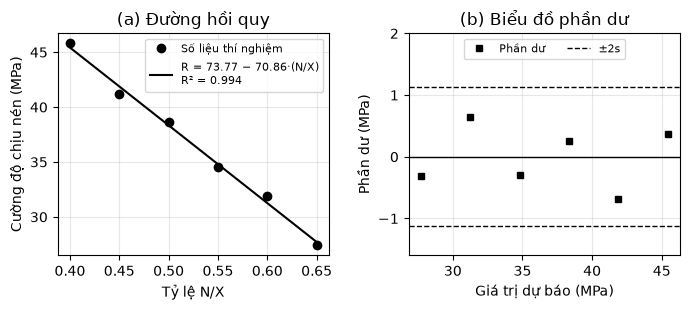

In [6]:
kq = stats.linregress(nx, fc)
print(f"R = {kq.intercept:.2f} + ({kq.slope:.2f})*(N/X), "
      f"R2 = {kq.rvalue**2:.4f}")
print(f"se(b1) = {kq.stderr:.3f} MPa, p = {kq.pvalue:.2e}")
fc_hat = kq.intercept + kq.slope * nx
e = fc - fc_hat
print("Phan du (MPa):", np.round(e, 2))
print(f"Max |phan du chuan hoa| = {np.max(np.abs(e)) / s:.2f}")
W, p_sw = stats.shapiro(e)
print(f"Shapiro-Wilk: W = {W:.3f}, p = {p_sw:.3f}")
dw = np.sum(np.diff(e) ** 2) / np.sum(e ** 2)
print(f"Durbin-Watson = {dw:.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.2))
x_ve = np.linspace(nx.min(), nx.max(), 100)
ax1.plot(nx, fc, "ko", label="Số liệu thí nghiệm")
nhan = (f"R = {kq.intercept:.2f} − {abs(kq.slope):.2f}·(N/X)"
        f"\nR² = {kq.rvalue**2:.3f}")
ax1.plot(x_ve, kq.intercept + kq.slope * x_ve, "k-",
         label=nhan)
ax1.set_title("(a) Đường hồi quy")
ax1.set_xlabel("Tỷ lệ N/X")
ax1.set_ylabel("Cường độ chịu nén (MPa)")
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3)
ax2.plot(fc_hat, e, "ks", ms=5, label="Phần dư")
ax2.axhline(0, color="k", lw=1)
ax2.axhline(2 * s, color="k", ls="--", lw=1, label="±2s")
ax2.axhline(-2 * s, color="k", ls="--", lw=1)
ax2.set_title("(b) Biểu đồ phần dư")
ax2.set_xlabel("Giá trị dự báo (MPa)")
ax2.set_ylabel("Phần dư (MPa)")
ax2.set_ylim(-1.6, 2.0)
ax2.legend(fontsize=8, loc="upper center", ncol=2)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Breusch-Pagan cho mo hinh hai bien (N/X, ln t)
e2_bp = e2 ** 2
hq_phu = LinearRegression().fit(X2, e2_bp)
LM = n9 * hq_phu.score(X2, e2_bp)
p_bp = stats.chi2.sf(LM, df=X2.shape[1])
print(f"Breusch-Pagan: LM = {LM:.2f}, df = {X2.shape[1]}, "
      f"p = {p_bp:.3f}")
dw2 = np.sum(np.diff(e2) ** 2) / np.sum(e2 ** 2)
print(f"Durbin-Watson (thu tu bang so lieu) = {dw2:.2f}")

Breusch-Pagan: LM = 3.17, df = 2, p = 0.205
Durbin-Watson (thu tu bang so lieu) = 1.88


*Ô dưới dùng thư viện statsmodels (có sẵn trên Colab; máy cá nhân cài bằng `pip install statsmodels`).*

In [ ]:
# can cai them: pip install statsmodels
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
Xs = sm.add_constant(X2)       # them cot 1 ung voi b0
kq_sm = sm.OLS(fc9, Xs).fit()
print(kq_sm.summary())   # he so, se, t, p, KTC, R2, R2_hc
print(durbin_watson(kq_sm.resid))
print(het_breuschpagan(kq_sm.resid, Xs))  # LM, p, F, p
x_moi = sm.add_constant([[0.50, np.log(14)]],
                        has_constant='add')
print(kq_sm.get_prediction(x_moi).summary_frame(alpha=0.05))

## HỒI QUY PHI TUYẾN VÀ HỒI QUY CHÍNH QUY HÓA

### Hồi quy đa thức

Bac 1: RMSE huan luyen = 1.43 mm, kiem tra = 1.51 mm
Bac 2: RMSE huan luyen = 0.62 mm, kiem tra = 0.66 mm
Bac 5: RMSE huan luyen = 0.31 mm, kiem tra = 1.47 mm


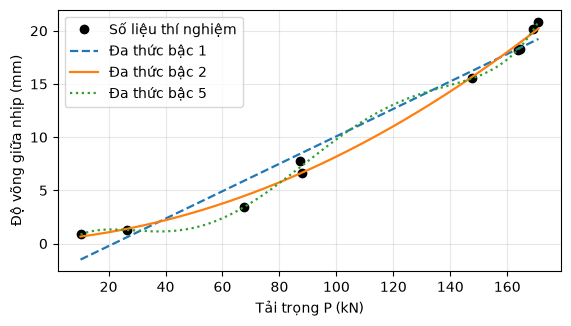

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (PolynomialFeatures,
                                   StandardScaler)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

def rmse(y, y_hat):
    return np.sqrt(mean_squared_error(y, y_hat))

# so lieu mo phong: tai P (kN), do vong giua nhip d (mm)
rng = np.random.default_rng(35)
def do_vong_that(p):
    return 0.06 * p + 2.0e-6 * p**3

P = np.sort(rng.uniform(10, 180, 10))
d = do_vong_that(P) + rng.normal(0, 0.6, P.size)
# tap kiem tra: 40 lan gia tai khac trong cung mien P
P_kt = rng.uniform(P.min(), P.max(), 40)
d_kt = do_vong_that(P_kt) + rng.normal(0, 0.6, P_kt.size)

P_ve = np.linspace(P.min(), P.max(), 300).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(P, d, "ko", label="Số liệu thí nghiệm")
kieu = {1: "--", 2: "-", 5: ":"}
for bac in [1, 2, 5]:
    mh = make_pipeline(
        PolynomialFeatures(degree=bac, include_bias=False),
        StandardScaler(), LinearRegression())
    mh.fit(P.reshape(-1, 1), d)
    e_hl = rmse(d, mh.predict(P.reshape(-1, 1)))
    e_kt = rmse(d_kt, mh.predict(P_kt.reshape(-1, 1)))
    print(f"Bac {bac}: RMSE huan luyen = {e_hl:.2f} mm,"
          f" kiem tra = {e_kt:.2f} mm")
    ax.plot(P_ve, mh.predict(P_ve), kieu[bac], lw=1.6,
            label=f"Đa thức bậc {bac}")
ax.set_xlabel("Tải trọng P (kN)")
ax.set_ylabel("Độ võng giữa nhịp (mm)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### Hồi quy phi tuyến theo tham số

f28 = 39.78 MPa, sai so chuan = 0.22 MPa
b   = 0.849, sai so chuan = 0.005
a   = 4.23 ngay
Khoang tin cay 95% cua f28: 39.31 - 40.25 MPa
Gioi han f28/b = 46.9 MPa
RMSE = 0.79 MPa
Du bao f(7) = 27.4 MPa
Du bao f(90) = 44.4 MPa


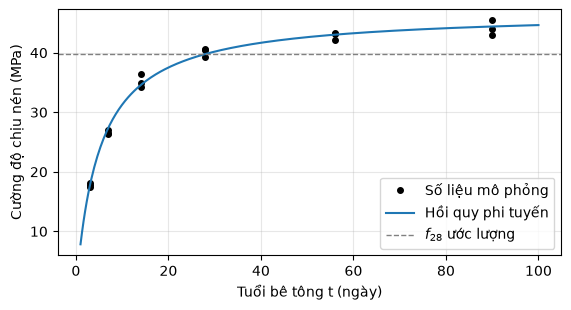

In [10]:
from scipy.optimize import curve_fit
from scipy import stats

# so lieu mo phong: 3 mau lap phuong o moi tuoi (ngay)
rng = np.random.default_rng(7)
t = np.repeat([3, 7, 14, 28, 56, 90], 3)
def f_tuoi(t, f28, b):
    a = 28 * (1 - b)          # rang buoc f(28) = f28
    return f28 * t / (a + b * t)
fc = f_tuoi(t, 40.0, 0.85) + rng.normal(0, 1.2, t.size)

p, pcov = curve_fit(f_tuoi, t, fc, p0=[35.0, 0.8])
se = np.sqrt(np.diag(pcov))
tq = stats.t.ppf(0.975, df=t.size - 2)
print(f"f28 = {p[0]:.2f} MPa, sai so chuan = {se[0]:.2f} MPa")
print(f"b   = {p[1]:.3f}, sai so chuan = {se[1]:.3f}")
print(f"a   = {28 * (1 - p[1]):.2f} ngay")
print(f"Khoang tin cay 95% cua f28: {p[0] - tq * se[0]:.2f}"
      f" - {p[0] + tq * se[0]:.2f} MPa")
print(f"Gioi han f28/b = {p[0] / p[1]:.1f} MPa")
e = fc - f_tuoi(t, *p)
print(f"RMSE = {np.sqrt(np.mean(e**2)):.2f} MPa")
for tt in [7, 90]:
    print(f"Du bao f({tt}) = {f_tuoi(tt, *p):.1f} MPa")

t_ve = np.linspace(1, 100, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(t, fc, "ko", ms=4, label="Số liệu mô phỏng")
ax.plot(t_ve, f_tuoi(t_ve, *p), "-", label="Hồi quy phi tuyến")
ax.axhline(p[0], ls="--", c="gray", lw=1,
           label="$f_{28}$ ước lượng")
ax.set_xlabel("Tuổi bê tông t (ngày)")
ax.set_ylabel("Cường độ chịu nén (MPa)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.show()

### Hồi quy Ridge và Lasso

In [11]:
from sklearn.linear_model import Ridge, Lasso

# so lieu mo phong: 30 vung thu tren ket cau be tong
rng = np.random.default_rng(4)
n = 30
q = rng.normal(0, 1, n)           # chat luong be tong (an)
R1 = 35 + 4 * q + rng.normal(0, 0.8, n)  # bat nay, sung 1
R2 = R1 + rng.normal(0, 0.4, n)          # bat nay, sung 2
V = 4.2 + 0.15 * q + rng.normal(0, 0.05, n)  # sieu am km/s
rho = 2380 + 25 * q + rng.normal(0, 12, n)   # kg/m3
am = rng.uniform(2, 6, n)         # do am be mat (%)
T = rng.uniform(15, 35, n)        # nhiet do khi do (do C)
fc = (38 + 0.3 * (R1 + R2 - 70) + 8 * (V - 4.2)
      - 0.8 * (am - 4) + rng.normal(0, 1.5, n))
ten = ["R1", "R2", "V", "rho", "do_am", "nhiet_do"]
X = pd.DataFrame(np.column_stack([R1, R2, V, rho, am, T]),
                 columns=ten)
print("He so tuong quan R1-R2:",
      round(np.corrcoef(R1, R2)[0, 1], 3))

he_so = {}
for nhan, est in [("OLS", LinearRegression()),
                  ("Ridge a=5", Ridge(alpha=5)),
                  ("Lasso a=0.3", Lasso(alpha=0.3))]:
    mh = make_pipeline(StandardScaler(), est).fit(X, fc)
    he_so[nhan] = mh[-1].coef_
print(pd.DataFrame(he_so, index=ten).round(2))

He so tuong quan R1-R2: 0.995
           OLS  Ridge a=5  Lasso a=0.3
R1        6.78       1.20         2.15
R2       -5.22       0.93         0.00
V         2.25       1.18         1.28
rho       0.54       0.77         0.54
do_am    -0.61      -0.66        -0.49
nhiet_do -0.37      -0.00         0.00


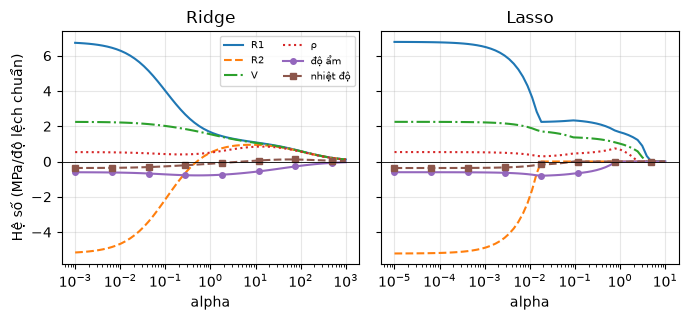

In [12]:
alphas = np.logspace(-3, 3, 60)
duong_r, duong_l = [], []
Xc = StandardScaler().fit_transform(X)
for a in alphas:
    duong_r.append(Ridge(alpha=a).fit(Xc, fc).coef_)
    duong_l.append(Lasso(alpha=a / 100, max_iter=10000)
                   .fit(Xc, fc).coef_)
duong_r, duong_l = np.array(duong_r), np.array(duong_l)

nhan = ["R1", "R2", "V", "ρ", "độ ẩm", "nhiệt độ"]
kieu = ["-", "--", "-.", ":", "-", "--"]
dau = ["", "", "", "", "o", "s"]
fig, ax = plt.subplots(1, 2, figsize=(7, 3.3), sharey=True)
for j in range(6):
    ax[0].semilogx(alphas, duong_r[:, j], kieu[j],
                   marker=dau[j], markevery=8, ms=4,
                   label=nhan[j])
    ax[1].semilogx(alphas / 100, duong_l[:, j], kieu[j],
                   marker=dau[j], markevery=8, ms=4)
ax[0].set_title("Ridge")
ax[1].set_title("Lasso")
ax[0].set_ylabel("Hệ số (MPa/độ lệch chuẩn)")
for a_ in ax:
    a_.set_xlabel("alpha")
    a_.axhline(0, c="k", lw=0.6)
    a_.grid(alpha=0.3)
ax[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

In [13]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold

kf5 = KFold(n_splits=5, shuffle=True, random_state=0)
r_gs = GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                    {"ridge__alpha": np.logspace(-3, 3, 61)},
                    cv=kf5, scoring="neg_root_mean_squared_error")
l_gs = GridSearchCV(make_pipeline(StandardScaler(),
                                  Lasso(max_iter=10000)),
                    {"lasso__alpha": np.logspace(-4, 0, 41)},
                    cv=kf5, scoring="neg_root_mean_squared_error")
for ten, gs in [("Ridge", r_gs), ("Lasso", l_gs)]:
    gs.fit(X, fc)
    k = list(gs.param_grid)[0]
    luoi = gs.param_grid[k]
    tb = -gs.cv_results_["mean_test_score"]
    se = gs.cv_results_["std_test_score"] / np.sqrt(5)
    # quy tac mot sai so chuan
    a_1se = luoi[tb <= tb.min() + se[tb.argmin()]].max()
    print(f"{ten}: alpha_CV = {luoi[tb.argmin()]:.3g}, "
          f"RMSE_CV = {tb.min():.2f} MPa")
    print("  he so:", np.round(gs.best_estimator_[-1].coef_, 2))
    mh = clone(gs.best_estimator_).set_params(**{k: a_1se})
    mh.fit(X, fc)
    print(f"  alpha_1SE = {a_1se:.3g}, he so:",
          np.round(mh[-1].coef_, 2))

Ridge: alpha_CV = 0.0501, RMSE_CV = 1.58 MPa
  he so: [ 4.94 -3.18  2.1   0.45 -0.69 -0.31]
  alpha_1SE = 15.8, he so: [ 1.01  0.92  0.98  0.85 -0.52  0.08]


Lasso: alpha_CV = 0.00501, RMSE_CV = 1.60 MPa
  he so: [ 5.38 -3.6   2.08  0.46 -0.67 -0.31]
  alpha_1SE = 0.501, he so: [ 1.98  0.    1.2   0.63 -0.3   0.  ]


## ỨNG DỤNG: DỰ BÁO CƯỜNG ĐỘ VẬT LIỆU, ĐỘ VÕNG VÀ SUY GIẢM KẾT CẤU

### Dự báo cường độ bê tông từ thành phần cấp phối

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# so lieu mo phong: 200 mau, thanh phan tinh cho 1 m3
rng = np.random.default_rng(21)
n = 200
df = pd.DataFrame({
    "xi_mang": rng.uniform(280, 450, n),    # kg/m3
    "tro_bay": rng.uniform(0, 120, n),      # kg/m3
    "nuoc": rng.uniform(150, 195, n),       # kg/m3
    "sieu_deo": rng.uniform(0, 8, n),       # kg/m3
    "cot_lieu": rng.uniform(1750, 1950, n), # kg/m3
    "tuoi": rng.choice([3, 7, 14, 28, 56, 90], n)})
nck = df.nuoc / (df.xi_mang + df.tro_bay)  # N/CKD
f28 = 100 * 0.12**nck * (1 + 0.015 * df.sieu_deo)
k_t = 1 + (0.20 + 0.0004 * df.tro_bay) * np.log(df.tuoi / 28)
df["fc"] = f28 * k_t + rng.normal(0, 2.0, n)
print("N/CKD:", round(nck.min(), 2), "-", round(nck.max(), 2))
print("fc (MPa):", round(df.fc.min(), 1), "-",
      round(df.fc.max(), 1))

N/CKD: 0.28 - 0.65
fc (MPa): 14.4 - 72.9


In [15]:
from sklearn.model_selection import GridSearchCV
X = df.drop(columns="fc")
y = df["fc"]
X_hl, X_kt, y_hl, y_kt = train_test_split(
    X, y, test_size=0.25, random_state=0)

def da_thuc(bac):
    return PolynomialFeatures(bac, include_bias=False)
mo_hinh = {
    "Tuyen tinh": make_pipeline(StandardScaler(),
                                LinearRegression()),
    "Da thuc bac 2": make_pipeline(da_thuc(2), StandardScaler(),
                                   LinearRegression()),
    "Da thuc bac 3": make_pipeline(da_thuc(3), StandardScaler(),
                                   LinearRegression()),
    "Ridge bac 3": GridSearchCV(make_pipeline(da_thuc(3),
                       StandardScaler(), Ridge()),
                       {"ridge__alpha": np.logspace(-3, 3, 61)},
                       cv=kf5, scoring="neg_root_mean_squared_error")}
for ten_mh, mh in mo_hinh.items():
    mh.fit(X_hl, y_hl)
    r_hl = rmse(y_hl, mh.predict(X_hl))
    y_du = mh.predict(X_kt)
    print(f"{ten_mh:14s} RMSE_hl = {r_hl:4.2f}"
          f"  RMSE_kt = {rmse(y_kt, y_du):4.2f} MPa"
          f"  R2_kt = {r2_score(y_kt, y_du):.3f}")
a_r = mo_hinh["Ridge bac 3"].best_params_["ridge__alpha"]
print(f"alpha chon boi GridSearchCV = {a_r:.2f}")

# dac trung ky thuat: thay tuoi bang ln(tuoi)
X_ln = X.assign(tuoi=np.log(X.tuoi))
mh_ln = make_pipeline(StandardScaler(), LinearRegression())
X_ln_hl, X_ln_kt = X_ln.loc[X_hl.index], X_ln.loc[X_kt.index]
mh_ln.fit(X_ln_hl, y_hl)
r_hl = rmse(y_hl, mh_ln.predict(X_ln_hl))
y_ln = mh_ln.predict(X_ln_kt)
print(f"{'TT ln(tuoi)':14s} RMSE_hl = {r_hl:4.2f}"
      f"  RMSE_kt = {rmse(y_kt, y_ln):4.2f} MPa"
      f"  R2_kt = {r2_score(y_kt, y_ln):.3f}")

Tuyen tinh     RMSE_hl = 5.88  RMSE_kt = 5.72 MPa  R2_kt = 0.829
Da thuc bac 2  RMSE_hl = 2.96  RMSE_kt = 3.08 MPa  R2_kt = 0.950
Da thuc bac 3  RMSE_hl = 1.48  RMSE_kt = 3.56 MPa  R2_kt = 0.934


Ridge bac 3    RMSE_hl = 1.86  RMSE_kt = 2.58 MPa  R2_kt = 0.965
alpha chon boi GridSearchCV = 0.04
TT ln(tuoi)    RMSE_hl = 2.76  RMSE_kt = 2.60 MPa  R2_kt = 0.965


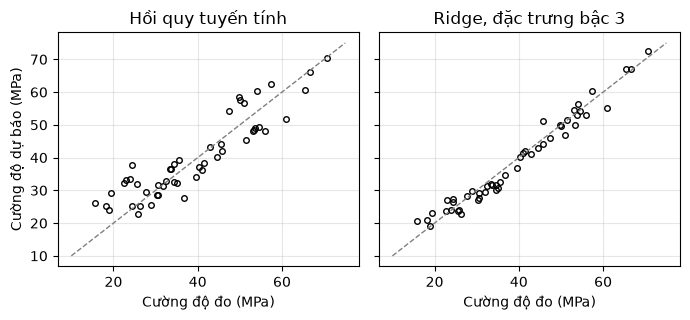

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(7, 3.3),
                       sharex=True, sharey=True)
for a_, k in zip(ax, ["Tuyen tinh", "Ridge bac 3"]):
    y_du = mo_hinh[k].predict(X_kt)
    a_.plot(y_kt, y_du, "o", ms=4, mfc="none", c="k")
    a_.plot([10, 75], [10, 75], "--", c="gray", lw=1)
    a_.set_xlabel("Cường độ đo (MPa)")
    a_.grid(alpha=0.3)
ax[0].set_title("Hồi quy tuyến tính")
ax[1].set_title("Ridge, đặc trưng bậc 3")
ax[0].set_ylabel("Cường độ dự báo (MPa)")
plt.tight_layout()
plt.show()

### Dự báo độ võng theo tải trọng và nhiệt độ

In [17]:
# so lieu quan trac mo phong: 2 lan do/ngay trong 365 ngay
rng = np.random.default_rng(5)
n = 730
ngay = np.arange(n) / 2.0
T = (26 + 7 * np.sin(2 * np.pi * (ngay - 110) / 365)
     + rng.normal(0, 2.5, n))                 # do C
P = rng.uniform(150, 450, n)                  # tai xe (kN)
k = np.ones(n)                       # do cung tuong doi
i0 = int(0.8 * n)
k[i0:] = 1 - 0.10 * np.linspace(0, 1, n - i0)  # giam 10%
dv = (0.30 + 0.0110 * P / k + 0.035 * (T - 25)
      + rng.normal(0, 0.12, n))               # do vong (mm)

# mo hinh tham chieu tu nua dau chuoi
n_tc = n // 2
X_d = np.column_stack([P, T])
mh_d = LinearRegression().fit(X_d[:n_tc], dv[:n_tc])
b0 = mh_d.intercept_
bP, bT = mh_d.coef_
print(f"d = {b0:.3f} + {bP:.5f}*P + {bT:.4f}*T  (mm)")
print(f"R2 (nua dau) = {mh_d.score(X_d[:n_tc], dv[:n_tc]):.3f}")
# do vong chuan hoa ve P = 300 kN, T = 20 do C
dv_ch = dv - bP * (P - 300) - bT * (T - 20)
print(f"Do vong chuan hoa, 30 ngay dau: "
      f"{dv_ch[:60].mean():.2f} mm")
print(f"Do vong chuan hoa, 30 ngay cuoi: "
      f"{dv_ch[-60:].mean():.2f} mm")

d = -0.580 + 0.01091*P + 0.0364*T  (mm)
R2 (nua dau) = 0.986
Do vong chuan hoa, 30 ngay dau: 3.41 mm
Do vong chuan hoa, 30 ngay cuoi: 3.72 mm


Do lech chuan phan du (tham chieu) = 0.121 mm
Gioi han kiem soat cua trung binh truot = 0.066 mm
Lan dau vuot gioi han: ngay 310
Bat dau giam do cung (mo phong): ngay 292


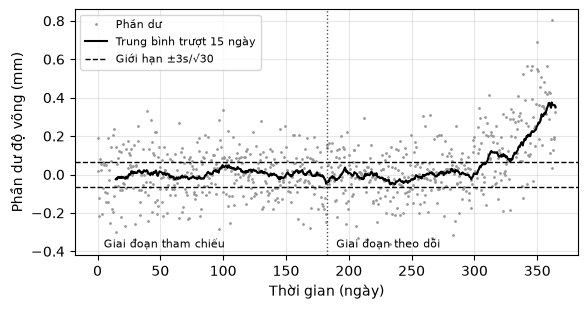

In [18]:
e = dv - mh_d.predict(X_d)
s = e[:n_tc].std(ddof=3)
e_tb = pd.Series(e).rolling(30).mean()    # trung binh 15 ngay
gh = 3 * s / np.sqrt(30)
print(f"Do lech chuan phan du (tham chieu) = {s:.3f} mm")
print(f"Gioi han kiem soat cua trung binh truot = {gh:.3f} mm")
vuot = np.where(e_tb > gh)[0]
print(f"Lan dau vuot gioi han: ngay {ngay[vuot[0]]:.0f}")
print(f"Bat dau giam do cung (mo phong): ngay {ngay[i0]:.0f}")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(ngay, e, ".", ms=2, c="0.6", label="Phần dư")
ax.plot(ngay, e_tb, "k-", lw=1.5,
        label="Trung bình trượt 15 ngày")
ax.axhline(gh, c="k", ls="--", lw=1, label="Giới hạn ±3s/√30")
ax.axhline(-gh, c="k", ls="--", lw=1)
ax.axvline(ngay[n_tc], c="0.3", ls=":", lw=1)
ax.text(5, -0.38, "Giai đoạn tham chiếu", fontsize=8)
ax.text(190, -0.38, "Giai đoạn theo dõi", fontsize=8)
ax.set_xlabel("Thời gian (ngày)")
ax.set_ylabel("Phần dư độ võng (mm)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", fontsize=8)
plt.show()

### Dự báo suy giảm tình trạng kết cấu theo thời gian

Ham mu: c0 = 97.3 (1.0), k = 0.0074 (0.0006) 1/nam
RMSE ham mu  = 3.15
RMSE bac hai = 3.12
Ham mu: cham nguong sau 66 nam (90%: 60 - 73 nam)
Bac hai: cham nguong sau 49 nam


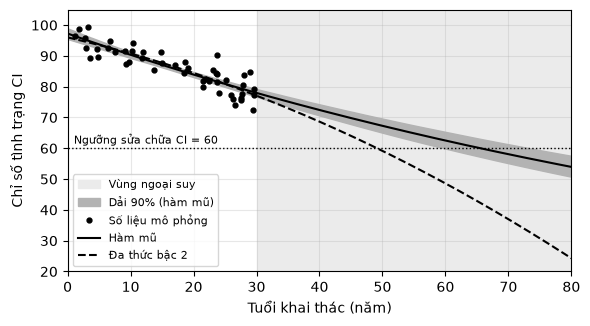

In [19]:
# so lieu mo phong: chi so tinh trang CI (0-100, thang gia dinh)
rng = np.random.default_rng(9)
tu = rng.uniform(1, 30, 48)                   # tuoi (nam)
ci = 96 - 0.45 * tu - 0.006 * tu**2 + rng.normal(0, 3.5, 48)

def mh_mu(t, c0, k):
    return c0 * np.exp(-k * t)
def mh_bac2(t, c0, b1, b2):
    return c0 - b1 * t - b2 * t**2
p_m, cov_m = curve_fit(mh_mu, tu, ci, p0=[90, 0.01])
p_q, cov_q = curve_fit(mh_bac2, tu, ci)
se_m = np.sqrt(np.diag(cov_m))
print(f"Ham mu: c0 = {p_m[0]:.1f} ({se_m[0]:.1f}),"
      f" k = {p_m[1]:.4f} ({se_m[1]:.4f}) 1/nam")
print("RMSE ham mu  =", round(rmse(ci, mh_mu(tu, *p_m)), 2))
print("RMSE bac hai =", round(rmse(ci, mh_bac2(tu, *p_q)), 2))

CI_NG = 60                                    # nguong sua chua
t_m = np.log(p_m[0] / CI_NG) / p_m[1]
mau = rng.multivariate_normal(p_m, cov_m, 2000)
t_mau = np.log(mau[:, 0] / CI_NG) / mau[:, 1]
lo, hi = np.percentile(t_mau, [5, 95])
print(f"Ham mu: cham nguong sau {t_m:.0f} nam"
      f" (90%: {lo:.0f} - {hi:.0f} nam)")
t_ve = np.linspace(0, 80, 801)
t_q = t_ve[np.argmax(mh_bac2(t_ve, *p_q) <= CI_NG)]
print(f"Bac hai: cham nguong sau {t_q:.0f} nam")

dai = np.array([mh_mu(t_ve, *m) for m in mau])
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.axvspan(30, 80, color="0.92", label="Vùng ngoại suy")
ax.fill_between(t_ve, *np.percentile(dai, [5, 95], axis=0),
                color="0.7", label="Dải 90% (hàm mũ)")
ax.plot(tu, ci, "ko", ms=3.5, label="Số liệu mô phỏng")
ax.plot(t_ve, mh_mu(t_ve, *p_m), "k-", label="Hàm mũ")
ax.plot(t_ve, mh_bac2(t_ve, *p_q), "k--", label="Đa thức bậc 2")
ax.axhline(CI_NG, c="k", ls=":", lw=1)
ax.text(1, CI_NG + 1.5, "Ngưỡng sửa chữa CI = 60", fontsize=8)
ax.set_xlim(0, 80)
ax.set_ylim(20, 105)
ax.set_xlabel("Tuổi khai thác (năm)")
ax.set_ylabel("Chỉ số tình trạng CI")
ax.grid(alpha=0.3)
ax.legend(loc="lower left", fontsize=8)
plt.show()

## BÀI TẬP